In [1]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      !pip install py3Dmol
      !pip install rdkit
      pbar.update(50)
      from rdkit import Chem
      from rdkit.Chem import Draw
      from rdkit.Chem.Draw import IPythonConsole
      from rdkit.Chem import AllChem # import the AllChem submodule from the Chem module
      from rdkit.Chem import rdDistGeom
      from rdkit.Chem import rdDepictor
      from IPython.display import Image
      import py3Dmol


      pbar.update(50)

  0%|          | 0/100 [00:00<?, ?it/s]

In [2]:
glucose = Chem.MolFromSmiles('OC[C@H]1OC(O)[C@@H]([C@H]([C@@H]1O)O)O')
glucose_H = Chem.AddHs(glucose)
glucose_embed = AllChem.EmbedMolecule(glucose_H)

#pymol

In [3]:
ps = rdDistGeom.ETKDGv3()
ps.clearConfs= False
cid = rdDistGeom.EmbedMolecule(glucose_H,ps)

In [4]:
#UNA MANERA de ALINEAR LOS CONFORMEROS

# Align conformers 1 and 2
from rdkit.Chem import rdMolAlign

# Get the conformers
conf1 = glucose_H.GetConformer(0)
conf2 = glucose_H.GetConformer(1)


# Perform the alignment
rdMolAlign.AlignMol(glucose_H, glucose_H, 1, 0)


# Visualize the aligned conformers
v1 = py3Dmol.view(width=400,height=400)
v1.removeAllModels()
IPythonConsole.addMolToView(glucose_H,v1,confId=0)
IPythonConsole.addMolToView(glucose_H,v1,confId=1)
v1.setStyle({'model': 0}, {'stick': {'colorscheme': 'greenCarbon'}})

v1.addStyle({'model': 1}, {'stick': {'colorscheme': 'pinkCarbon'}})
v1.zoomTo()
v1.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

# Distintas moleculas

Vamos a comparar distintas moléculas

In [5]:
manose = Chem.MolFromSmiles('OC[C@H]1OC(O)[C@@H](O)[C@@H](O)[C@@H]1O')
mol2 = Chem.AddHs(manose)
AllChem.EmbedMolecule(mol2)
cid = rdDistGeom.EmbedMolecule(mol2,ps)

v3 = py3Dmol.view(width=400,height=400)
v3.removeAllModels()

IPythonConsole.addMolToView(mol2, v3, confId=-1)
v3.setStyle({'stick':{'colorscheme':'pinkCarbon'}}) # Style as sticks for better visualization

v3.zoomTo()
print('Manosa')
v3.show()


Manosa


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Vamos a comparar la glucosa y la manosa

In [6]:
galactose = Chem.MolFromSmiles('C([C@@H]1[C@@H]([C@@H]([C@H](C(O1)O)O)O)O)O')
mol3 = Chem.AddHs(galactose)
AllChem.EmbedMolecule(mol3)
cid = rdDistGeom.EmbedMolecule(mol3,ps)
v5 = py3Dmol.view(width=400,height=400)
v5.removeAllModels()

IPythonConsole.addMolToView(mol3, v5, confId=-1)
v5.setStyle({'stick':{'colorscheme':'blueCarbon'}}) # Style as sticks for better visualization
v5.zoomTo()
# v5.setStyle({'stick':{'colorscheme':'greenCarbon'}})
print('Galactose')
v5.show()


Galactose


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

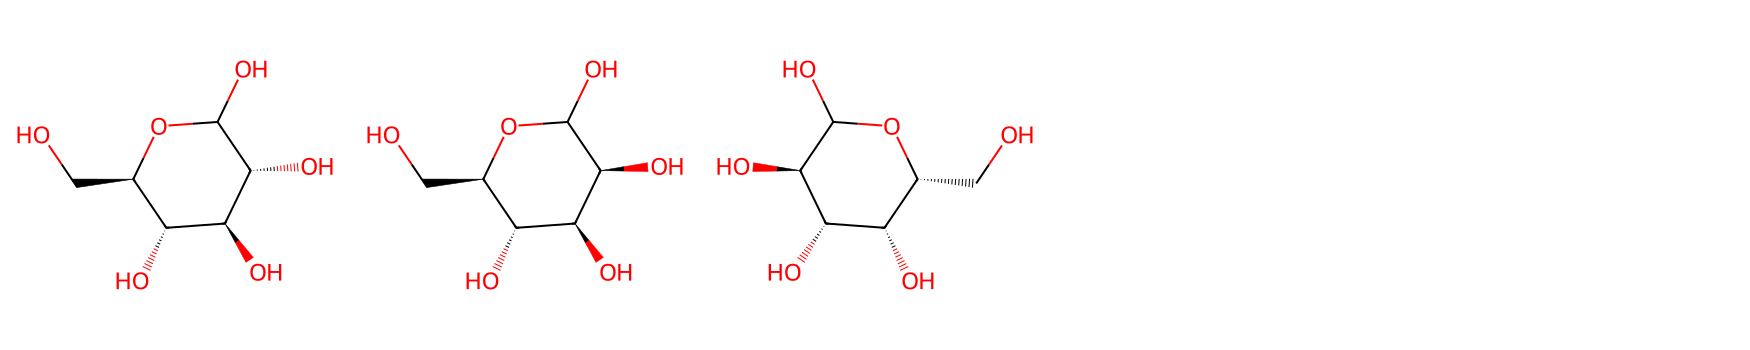

In [7]:
# Comparamos estructuras 2D
img = Draw.MolsToGridImage((glucose, manose, galactose), subImgSize=(350,350), molsPerRow=5)
display(img)

In [8]:
mol1 = glucose_H
cid = rdDistGeom.EmbedMolecule(mol2,ps)
v4 = py3Dmol.view(width=400,height=400)
v4.removeAllModels()

# lis = [mol1, mol2,mol3]

# Display the aligned molecules using py3Dmol
rmsd = AllChem.AlignMol(mol3, mol1)

# Add the first molecule (reference)
IPythonConsole.addMolToView(mol1, v4, confId=0)
IPythonConsole.addMolToView(mol3, v4, confId=0)

#v4.setStyle({'stick':{'colorscheme':'pinkCarbon'}}) # Target the second model
v4.setStyle({'model': 0}, {'stick':{'colorscheme':'greenCarbon'}})
v4.addStyle({'model': 1}, {'stick':{'colorscheme':'blueCarbon'}})


v4.zoomTo()
v4.show()




print(f'')
print(f'RMSD: {rmsd:.2f}')

3Dmol.js failed to load for some reason. Please check your browser console for error messages.


RMSD: 1.08


### Alinear múltiples moléculas a una referencia común

Dado que `AlignMol` alinea una molécula ('probe') a otra ('reference'), para alinear múltiples moléculas, podemos seleccionar una como referencia y alinear todas las demás a esa referencia. Luego, visualizamos todas las moléculas alineadas en la misma vista.

In [9]:
alosa = Chem.MolFromSmiles('C([C@@H]1[C@H]([C@H]([C@H](C(O1)O)O)O)O)O')
mol4 = Chem.AddHs(alosa)
AllChem.EmbedMolecule(mol4)
cid = rdDistGeom.EmbedMolecule(mol4,ps)


In [11]:
# Definir una lista de moléculas para alinear
mols_to_align = [
    ("Glucosa (Referencia)", glucose_H, 'greenCarbon'), # Referencia
    ("Manosa", mol2, 'pinkCarbon'),
    ("Galactosa", mol3, 'blueCarbon'),
    ('Alosa', mol4, 'orangeCarbon')

]

# La primera molécula en la lista será nuestra referencia
reference_mol_name, reference_mol, reference_color = mols_to_align[0]

v_multi = py3Dmol.view(width=600, height=400)
v_multi.removeAllModels()

# Añadir la molécula de referencia a la vista
IPythonConsole.addMolToView(reference_mol, v_multi, confId=0)

print(f"Alineando moléculas a: {reference_mol_name}")

# Iterar sobre el resto de las moléculas y alinearlas a la referencia
for i, (name, probe_mol, color) in enumerate(mols_to_align[1:]):
    # Asegurarse de que la molécula probe tenga conformeros embedidos si no se hizo antes
    # (ya lo hemos hecho para mol2 y mol3 en celdas anteriores)
    # Si no fuera el caso, se debería llamar a AllChem.EmbedMolecule(probe_mol)

    # Alinear la molécula probe a la referencia
    rmsd = AllChem.AlignMol(probe_mol, reference_mol)

    # Añadir la molécula alineada a la vista. El índice del modelo será i+1 ya que la referencia es 0.
    IPythonConsole.addMolToView(probe_mol, v_multi, confId=0)

    # Imprimir el RMSD
    print(f"RMSD de {name} con respecto a {reference_mol_name}: {rmsd:.2f}")

# Establecer los estilos para cada molécula
v_multi.setStyle({'model': 0}, {'stick': {'colorscheme': reference_color}})
for i, (_, _, color) in enumerate(mols_to_align[1:]):
    v_multi.addStyle({'model': i + 1}, {'stick': {'colorscheme': color}})

v_multi.zoomTo()
v_multi.show()

Alineando moléculas a: Glucosa (Referencia)
RMSD de Manosa con respecto a Glucosa (Referencia): 1.13
RMSD de Galactosa con respecto a Glucosa (Referencia): 1.08
RMSD de Alosa con respecto a Glucosa (Referencia): 1.57


3Dmol.js failed to load for some reason. Please check your browser console for error messages.